# Cell 1: Install and import necessary libraries

In [1]:
!pip install -q grad-cam lime torchmetrics timm

import os
import gc
import copy
import time
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision
from torchvision import transforms, models

import timm

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

print("Torch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Timm version:", timm.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Number of GPUs:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 50.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Torch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
Timm version: 1.0.26
CUDA available: True
Number of GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


# Cell 2: Configuration, seeding, and device setup


In [2]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MULTI_GPU = torch.cuda.device_count() > 1

DATA_DIR = "/kaggle/input/datasets/tahsinstudy26/mango-ripeness-classification/Mango Shelf-Life Dataset"

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4
NUM_EPOCHS = 35
PATIENCE = 5
LEARNING_RATE = 1e-4
NUM_CLASSES = 5

TRAIN_SPLIT = 0.70
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15

OUTPUT_DIR = "/kaggle/working/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Device:", DEVICE)
print("Multi GPU:", MULTI_GPU)
print("Data directory exists:", os.path.exists(DATA_DIR))
print("Output directory:", OUTPUT_DIR)
print("Split ratio -> Train: {}, Val: {}, Test: {}".format(TRAIN_SPLIT, VAL_SPLIT, TEST_SPLIT))

Device: cuda
Multi GPU: True
Data directory exists: True
Output directory: /kaggle/working/outputs
Split ratio -> Train: 0.7, Val: 0.15, Test: 0.15


# Cell 3: Inspect dataset structure and count images per class


Classes found: ['Fully Ripe', 'Overripe', 'Perished', 'Semiripe', 'Unripe']
Number of classes: 5

Class distribution:
  Fully Ripe: 841
  Overripe: 896
  Perished: 184
  Semiripe: 1157
  Unripe: 1350

Total images: 4428


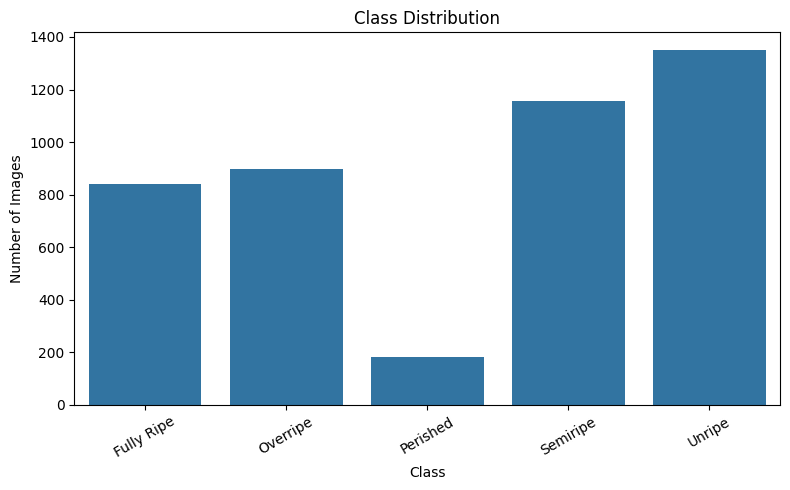

In [3]:
class_names = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
print("Classes found:", class_names)
print("Number of classes:", len(class_names))

VALID_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

class_counts = {}
all_filepaths = []
all_labels = []

for label_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(DATA_DIR, class_name)
    files = [f for f in os.listdir(class_dir) if f.lower().endswith(VALID_EXTENSIONS)]
    class_counts[class_name] = len(files)
    for f in files:
        all_filepaths.append(os.path.join(class_dir, f))
        all_labels.append(label_idx)

print("\nClass distribution:")
for cname, count in class_counts.items():
    print(f"  {cname}: {count}")

print("\nTotal images:", len(all_filepaths))

plt.figure(figsize=(8, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()))
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "class_distribution.png"), dpi=150)
plt.show()

# Cell 4: Visualize sample images from each class


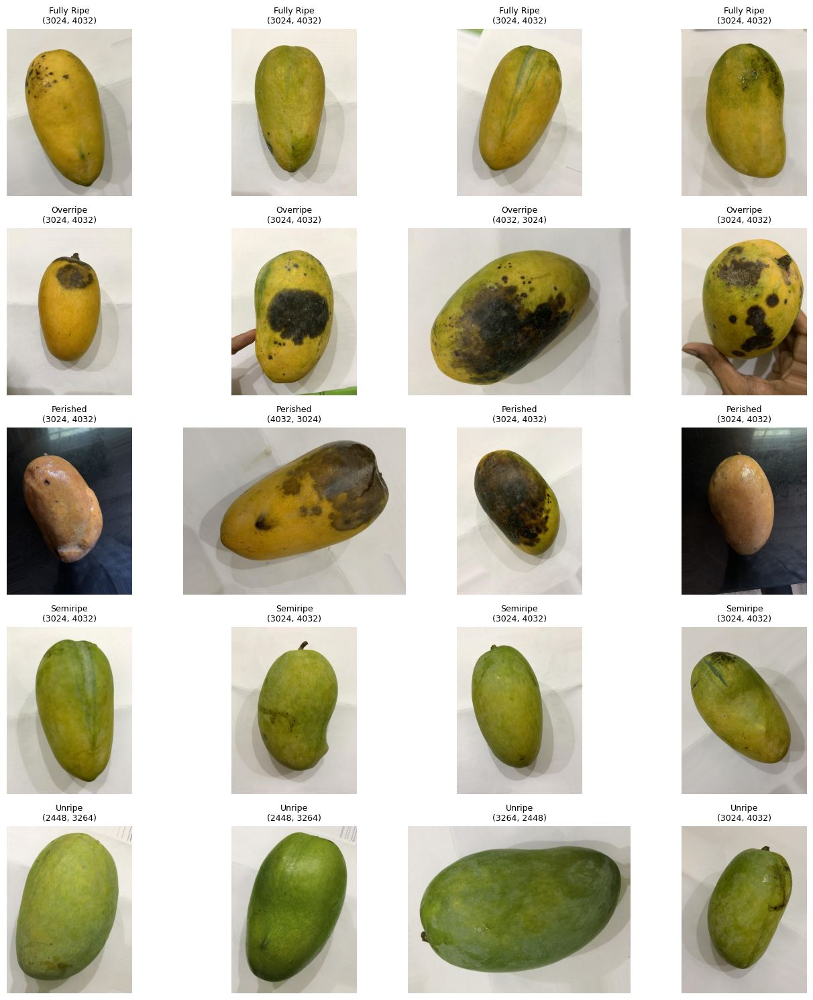

Sample image properties:
  Fully Ripe/image_0_5031.jpg: size=(3024, 4032), mode=RGB
  Overripe/image_0_8031.jpg: size=(3024, 4032), mode=RGB


In [4]:
fig, axes = plt.subplots(len(class_names), 4, figsize=(14, 3 * len(class_names)))

for row, class_name in enumerate(class_names):
    class_dir = os.path.join(DATA_DIR, class_name)
    files = [f for f in os.listdir(class_dir) if f.lower().endswith(VALID_EXTENSIONS)]
    sample_files = random.sample(files, min(4, len(files)))

    for col in range(4):
        ax = axes[row, col]
        if col < len(sample_files):
            img_path = os.path.join(class_dir, sample_files[col])
            img = Image.open(img_path).convert("RGB")
            ax.imshow(img)
            ax.set_title(f"{class_name}\n{img.size}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "sample_images.png"), dpi=150)
plt.show()

print("Sample image properties:")
for class_name in class_names[:2]:
    class_dir = os.path.join(DATA_DIR, class_name)
    files = [f for f in os.listdir(class_dir) if f.lower().endswith(VALID_EXTENSIONS)]
    sample_file = random.choice(files)
    img = Image.open(os.path.join(class_dir, sample_file))
    print(f"  {class_name}/{sample_file}: size={img.size}, mode={img.mode}")

# Cell 5: Split dataset into train, validation, and test sets (70-15-15, stratified)


In [5]:
all_filepaths = np.array(all_filepaths)
all_labels = np.array(all_labels)

# First split: 70% train, 30% temp (val + test)
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_filepaths, all_labels,
    test_size=(VAL_SPLIT + TEST_SPLIT),
    stratify=all_labels,
    random_state=SEED
)

# Second split: split temp into 50% val, 50% test (i.e. 15% and 15% of original)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.5,
    stratify=temp_labels,
    random_state=SEED
)

print("Train samples:", len(train_paths))
print("Validation samples:", len(val_paths))
print("Test samples:", len(test_paths))
print("Total:", len(train_paths) + len(val_paths) + len(test_paths))

def print_distribution(labels, name):
    print(f"\n{name} distribution:")
    unique, counts = np.unique(labels, return_counts=True)
    for u, c in zip(unique, counts):
        print(f"  {class_names[u]}: {c} ({c/len(labels)*100:.1f}%)")

print_distribution(train_labels, "Train")
print_distribution(val_labels, "Validation")
print_distribution(test_labels, "Test")

Train samples: 3099
Validation samples: 664
Test samples: 665
Total: 4428

Train distribution:
  Fully Ripe: 588 (19.0%)
  Overripe: 627 (20.2%)
  Perished: 129 (4.2%)
  Semiripe: 810 (26.1%)
  Unripe: 945 (30.5%)

Validation distribution:
  Fully Ripe: 127 (19.1%)
  Overripe: 134 (20.2%)
  Perished: 28 (4.2%)
  Semiripe: 173 (26.1%)
  Unripe: 202 (30.4%)

Test distribution:
  Fully Ripe: 126 (18.9%)
  Overripe: 135 (20.3%)
  Perished: 27 (4.1%)
  Semiripe: 174 (26.2%)
  Unripe: 203 (30.5%)


# Cell 6: Custom Dataset class, transforms, and DataLoaders


In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


class MangoDataset(Dataset):
    def __init__(self, filepaths, labels, transform=None):
        self.filepaths = filepaths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        img_path = self.filepaths[idx]
        image = Image.open(img_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = MangoDataset(train_paths, train_labels, transform=train_transform)
val_dataset = MangoDataset(val_paths, val_labels, transform=eval_transform)
test_dataset = MangoDataset(test_paths, test_labels, transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, pin_memory=True, drop_last=False)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

sample_images, sample_labels = next(iter(train_loader))
print("\nSample batch image shape:", sample_images.shape)
print("Sample batch label shape:", sample_labels.shape)
print("Sample labels:", sample_labels[:10].tolist())

Train batches: 97
Validation batches: 21
Test batches: 21

Sample batch image shape: torch.Size([32, 3, 224, 224])
Sample batch label shape: torch.Size([32])
Sample labels: [3, 4, 1, 3, 3, 2, 0, 4, 2, 4]


# Cell 7: Class weights and reusable training/evaluation functions


In [7]:
from tqdm.notebook import tqdm
import sys

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)
class_weights_tensor = torch.tensor(class_weights_array, dtype=torch.float32).to(DEVICE)

print("Class weights:")
for cname, w in zip(class_names, class_weights_array):
    print(f"  {cname}: {w:.4f}")


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(loader, desc="Training", leave=False, file=sys.stdout)
    for images, labels in progress_bar:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        batch_acc = (preds == labels).float().mean().item()
        progress_bar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{batch_acc:.4f}")

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate(model, loader, criterion, device, desc="Validating"):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    progress_bar = tqdm(loader, desc=desc, leave=False, file=sys.stdout)
    for images, labels in progress_bar:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        batch_acc = (preds == labels).float().mean().item()
        progress_bar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{batch_acc:.4f}")

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc, all_preds, all_labels


def train_model(model, model_name, train_loader, val_loader, criterion, optimizer, scheduler,
                 num_epochs, patience, device):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_model_weights = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0
    best_epoch = 0

    total_start = time.time()

    for epoch in range(num_epochs):
        epoch_start = time.time()
        print(f"\n[{model_name}] Epoch {epoch+1}/{num_epochs}", flush=True)

        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)

        if scheduler is not None:
            scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        epoch_time = time.time() - epoch_start

        print(f"[{model_name}] Epoch {epoch+1}/{num_epochs} summary "
              f"- train_loss: {train_loss:.4f} - train_acc: {train_acc:.4f} "
              f"- val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f} "
              f"- time: {epoch_time:.1f}s", flush=True)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_weights = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
            best_epoch = epoch + 1
            print("Validation loss improved. Saving best weights.", flush=True)
        else:
            epochs_no_improve += 1
            print(f"No improvement for {epochs_no_improve} epoch(s).", flush=True)

        if epochs_no_improve >= patience:
            print(f"\nEarly stopping triggered at epoch {epoch+1}. Best epoch: {best_epoch}", flush=True)
            break

    total_time = time.time() - total_start
    print(f"\nTotal training time for {model_name}: {total_time/60:.2f} minutes", flush=True)

    model.load_state_dict(best_model_weights)
    return model, history, best_epoch


print("\nHelper functions defined successfully.")

Class weights:
  Fully Ripe: 1.0541
  Overripe: 0.9885
  Perished: 4.8047
  Semiripe: 0.7652
  Unripe: 0.6559

Helper functions defined successfully.


# Cell 8: Evaluation and plotting utility functions


In [8]:
def plot_loss_curves(history, model_name, save_dir=OUTPUT_DIR):
    epochs_range = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", marker="o")
    axes[0].plot(epochs_range, history["val_loss"], label="Validation Loss", marker="o")
    axes[0].set_title(f"{model_name} - Loss Curves")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs_range, history["train_acc"], label="Train Accuracy", marker="o")
    axes[1].plot(epochs_range, history["val_acc"], label="Validation Accuracy", marker="o")
    axes[1].set_title(f"{model_name} - Accuracy Curves")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{model_name}_loss_curves.png"), dpi=150)
    plt.show()


def plot_confusion_matrix(y_true, y_pred, model_name, class_names, save_dir=OUTPUT_DIR):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{model_name}_confusion_matrix.png"), dpi=150)
    plt.show()


def print_classification_report(y_true, y_pred, model_name, class_names):
    print(f"\n{'='*60}")
    print(f"Classification Report - {model_name}")
    print(f"{'='*60}")
    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
    print(report)
    return report


def full_evaluation(model, model_name, test_loader, criterion, device, class_names, history=None):
    test_loss, test_acc, test_preds, test_true = evaluate(model, test_loader, criterion, device)

    print(f"\n{model_name} - Test Loss: {test_loss:.4f} - Test Accuracy: {test_acc:.4f}")

    if history is not None:
        plot_loss_curves(history, model_name)

    print_classification_report(test_true, test_preds, model_name, class_names)
    plot_confusion_matrix(test_true, test_preds, model_name, class_names)

    return test_loss, test_acc, test_preds, test_true


results_summary = {}
models_dict = {}
histories_dict = {}

print("Evaluation utility functions defined successfully.")

Evaluation utility functions defined successfully.


# Cell 9: Model 1 - ResNet50 - Setup and Training


In [9]:
set_seed(SEED)

resnet_model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
num_features = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_features, NUM_CLASSES)
resnet_model = resnet_model.to(DEVICE)

if MULTI_GPU:
    resnet_model = nn.DataParallel(resnet_model)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.AdamW(resnet_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

print("Starting training: ResNet50", flush=True)
resnet_model, resnet_history, resnet_best_epoch = train_model(
    resnet_model, "ResNet50",
    train_loader, val_loader,
    criterion, optimizer, scheduler,
    NUM_EPOCHS, PATIENCE, DEVICE
)

torch.save(resnet_model.state_dict(), os.path.join(OUTPUT_DIR, "resnet50_best.pth"))
print("ResNet50 weights saved.")

models_dict["ResNet50"] = resnet_model
histories_dict["ResNet50"] = resnet_history

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 203MB/s]


Starting training: ResNet50

[ResNet50] Epoch 1/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

Validating:   0%|          | 0/21 [00:00<?, ?it/s]

[ResNet50] Epoch 1/35 summary - train_loss: 0.8101 - train_acc: 0.6941 - val_loss: 0.3620 - val_acc: 0.8509 - time: 250.1s
Validation loss improved. Saving best weights.

[ResNet50] Epoch 2/35


... (38 outputs left out)

[ResNet50] Epoch 14/35 summary - train_loss: 0.0671 - train_acc: 0.9771 - val_loss: 0.0666 - val_acc: 0.9759 - time: 258.4s
No improvement for 4 epoch(s).

[ResNet50] Epoch 15/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

Validating:   0%|          | 0/21 [00:00<?, ?it/s]

[ResNet50] Epoch 15/35 summary - train_loss: 0.0654 - train_acc: 0.9758 - val_loss: 0.0722 - val_acc: 0.9744 - time: 250.3s
No improvement for 5 epoch(s).

Early stopping triggered at epoch 15. Best epoch: 10

Total training time for ResNet50: 62.89 minutes
ResNet50 weights saved.


# Cell 10: Model 1 - ResNet50 - Full Evaluation


Validating:   0%|          | 0/21 [00:00<?, ?it/s]


ResNet50 - Test Loss: 0.0799 - Test Accuracy: 0.9759


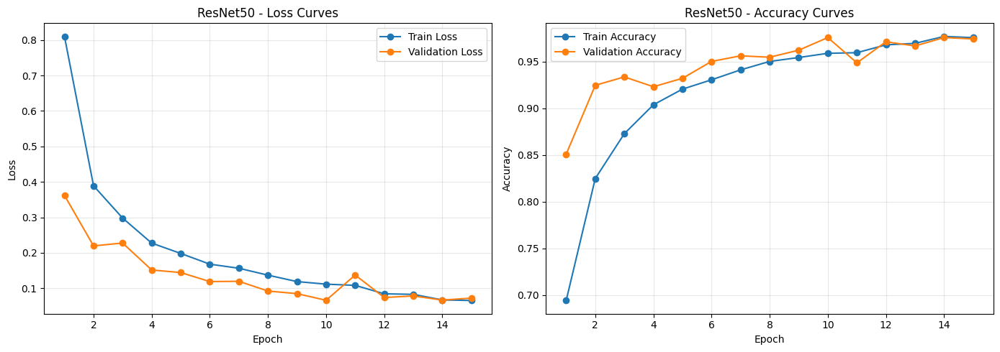


Classification Report - ResNet50
              precision    recall  f1-score   support

  Fully Ripe     0.9748    0.9206    0.9469       126
    Overripe     0.9362    0.9778    0.9565       135
    Perished     0.9310    1.0000    0.9643        27
    Semiripe     0.9942    0.9828    0.9884       174
      Unripe     0.9951    1.0000    0.9975       203

    accuracy                         0.9759       665
   macro avg     0.9663    0.9762    0.9707       665
weighted avg     0.9764    0.9759    0.9759       665



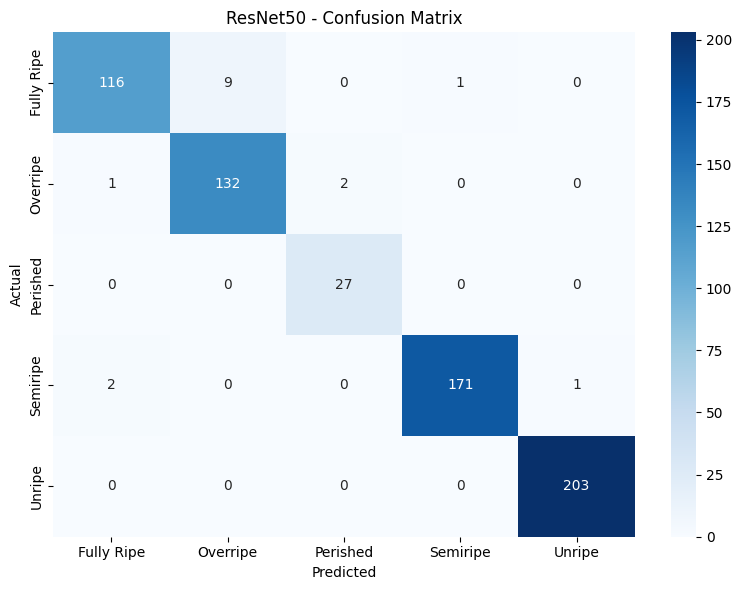


ResNet50 evaluation complete.
Test Accuracy: 0.9759
Test Loss: 0.0799


In [10]:
resnet_test_loss, resnet_test_acc, resnet_test_preds, resnet_test_true = full_evaluation(
    resnet_model, "ResNet50", test_loader, criterion, DEVICE, class_names, history=resnet_history
)

results_summary["ResNet50"] = {
    "test_loss": resnet_test_loss,
    "test_acc": resnet_test_acc,
    "best_epoch": resnet_best_epoch,
    "preds": resnet_test_preds,
    "true": resnet_test_true
}

print("\nResNet50 evaluation complete.")
print(f"Test Accuracy: {resnet_test_acc:.4f}")
print(f"Test Loss: {resnet_test_loss:.4f}")

# Cell 11: Model 2 - EfficientNet-B0 - Setup and Training


In [11]:
set_seed(SEED)

effnet_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
num_features = effnet_model.classifier[1].in_features
effnet_model.classifier[1] = nn.Linear(num_features, NUM_CLASSES)
effnet_model = effnet_model.to(DEVICE)

if MULTI_GPU:
    effnet_model = nn.DataParallel(effnet_model)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.AdamW(effnet_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

print("Starting training: EfficientNet-B0", flush=True)
effnet_model, effnet_history, effnet_best_epoch = train_model(
    effnet_model, "EfficientNet-B0",
    train_loader, val_loader,
    criterion, optimizer, scheduler,
    NUM_EPOCHS, PATIENCE, DEVICE
)

torch.save(effnet_model.state_dict(), os.path.join(OUTPUT_DIR, "efficientnet_b0_best.pth"))
print("EfficientNet-B0 weights saved.")

models_dict["EfficientNet-B0"] = effnet_model
histories_dict["EfficientNet-B0"] = effnet_history

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 143MB/s]


Starting training: EfficientNet-B0

[EfficientNet-B0] Epoch 1/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

Validating:   0%|          | 0/21 [00:00<?, ?it/s]

[EfficientNet-B0] Epoch 1/35 summary - train_loss: 0.9313 - train_acc: 0.6631 - val_loss: 0.3768 - val_acc: 0.8373 - time: 250.7s
Validation loss improved. Saving best weights.

[EfficientNet-B0] Epoch 2/35


... (68 outputs left out)

[EfficientNet-B0] Epoch 24/35 summary - train_loss: 0.0602 - train_acc: 0.9758 - val_loss: 0.0732 - val_acc: 0.9774 - time: 256.6s
No improvement for 4 epoch(s).

[EfficientNet-B0] Epoch 25/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

Validating:   0%|          | 0/21 [00:00<?, ?it/s]

[EfficientNet-B0] Epoch 25/35 summary - train_loss: 0.0560 - train_acc: 0.9790 - val_loss: 0.0721 - val_acc: 0.9789 - time: 251.6s
No improvement for 5 epoch(s).

Early stopping triggered at epoch 25. Best epoch: 20

Total training time for EfficientNet-B0: 108.16 minutes
EfficientNet-B0 weights saved.


# Cell 12: Model 2 - EfficientNet-B0 - Full Evaluation


Validating:   0%|          | 0/21 [00:00<?, ?it/s]


EfficientNet-B0 - Test Loss: 0.0759 - Test Accuracy: 0.9714


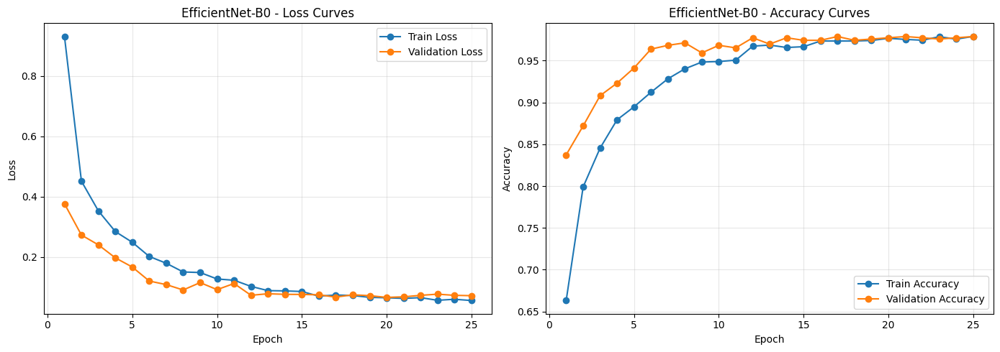


Classification Report - EfficientNet-B0
              precision    recall  f1-score   support

  Fully Ripe     0.9435    0.9286    0.9360       126
    Overripe     0.9420    0.9630    0.9524       135
    Perished     0.9310    1.0000    0.9643        27
    Semiripe     0.9883    0.9713    0.9797       174
      Unripe     1.0000    1.0000    1.0000       203

    accuracy                         0.9714       665
   macro avg     0.9610    0.9726    0.9665       665
weighted avg     0.9717    0.9714    0.9714       665



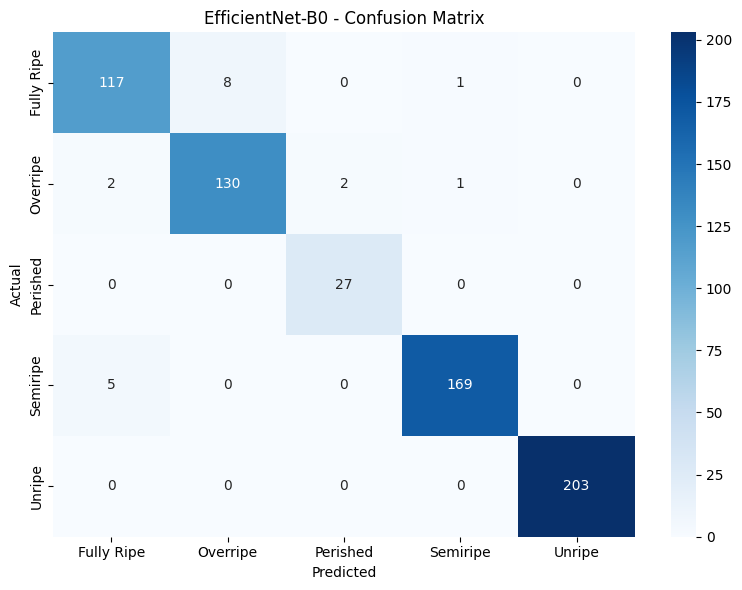


EfficientNet-B0 evaluation complete.
Test Accuracy: 0.9714
Test Loss: 0.0759


In [12]:
effnet_test_loss, effnet_test_acc, effnet_test_preds, effnet_test_true = full_evaluation(
    effnet_model, "EfficientNet-B0", test_loader, criterion, DEVICE, class_names, history=effnet_history
)

results_summary["EfficientNet-B0"] = {
    "test_loss": effnet_test_loss,
    "test_acc": effnet_test_acc,
    "best_epoch": effnet_best_epoch,
    "preds": effnet_test_preds,
    "true": effnet_test_true
}

print("\nEfficientNet-B0 evaluation complete.")
print(f"Test Accuracy: {effnet_test_acc:.4f}")
print(f"Test Loss: {effnet_test_loss:.4f}")

# Cell 13: Model 3 - DenseNet121 - Setup and Training


In [13]:
set_seed(SEED)

densenet_model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
num_features = densenet_model.classifier.in_features
densenet_model.classifier = nn.Linear(num_features, NUM_CLASSES)
densenet_model = densenet_model.to(DEVICE)

if MULTI_GPU:
    densenet_model = nn.DataParallel(densenet_model)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.AdamW(densenet_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

print("Starting training: DenseNet121", flush=True)
densenet_model, densenet_history, densenet_best_epoch = train_model(
    densenet_model, "DenseNet121",
    train_loader, val_loader,
    criterion, optimizer, scheduler,
    NUM_EPOCHS, PATIENCE, DEVICE
)

torch.save(densenet_model.state_dict(), os.path.join(OUTPUT_DIR, "densenet121_best.pth"))
print("DenseNet121 weights saved.")

models_dict["DenseNet121"] = densenet_model
histories_dict["DenseNet121"] = densenet_history

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 151MB/s]

Starting training: DenseNet121



[DenseNet121] Epoch 1/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

Validating:   0%|          | 0/21 [00:00<?, ?it/s]

... (84 outputs left out)

[DenseNet121] Epoch 29/35 summary - train_loss: 0.0334 - train_acc: 0.9874 - val_loss: 0.0671 - val_acc: 0.9789 - time: 248.0s
No improvement for 4 epoch(s).

[DenseNet121] Epoch 30/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

Validating:   0%|          | 0/21 [00:00<?, ?it/s]

[DenseNet121] Epoch 30/35 summary - train_loss: 0.0321 - train_acc: 0.9887 - val_loss: 0.0649 - val_acc: 0.9759 - time: 247.2s
No improvement for 5 epoch(s).

Early stopping triggered at epoch 30. Best epoch: 25

Total training time for DenseNet121: 123.59 minutes
DenseNet121 weights saved.


# Cell 14: Model 3 - DenseNet121 - Full Evaluation


Validating:   0%|          | 0/21 [00:00<?, ?it/s]


DenseNet121 - Test Loss: 0.0610 - Test Accuracy: 0.9744


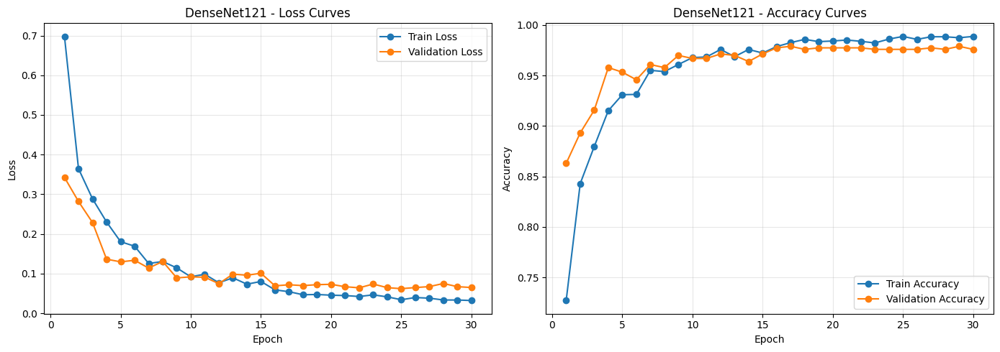


Classification Report - DenseNet121
              precision    recall  f1-score   support

  Fully Ripe     0.9744    0.9048    0.9383       126
    Overripe     0.9225    0.9704    0.9458       135
    Perished     0.9310    1.0000    0.9643        27
    Semiripe     0.9943    0.9943    0.9943       174
      Unripe     1.0000    1.0000    1.0000       203

    accuracy                         0.9744       665
   macro avg     0.9644    0.9739    0.9685       665
weighted avg     0.9751    0.9744    0.9744       665



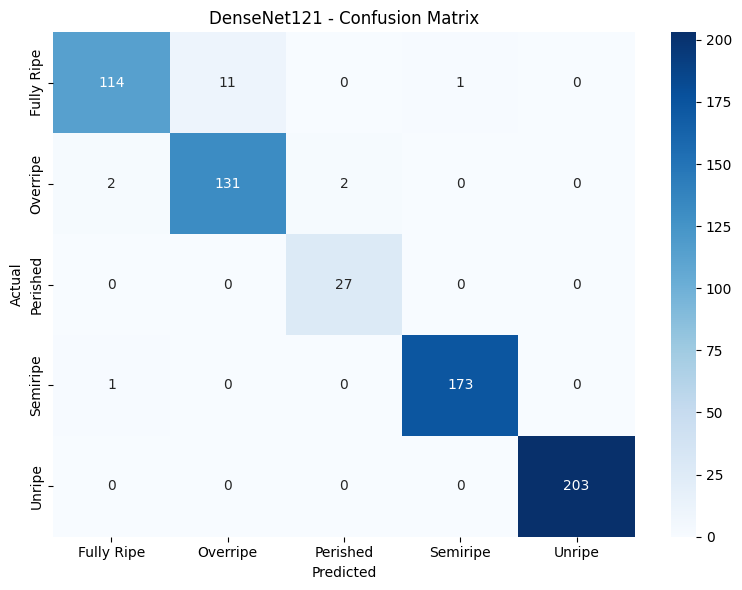


DenseNet121 evaluation complete.
Test Accuracy: 0.9744
Test Loss: 0.0610


In [14]:
densenet_test_loss, densenet_test_acc, densenet_test_preds, densenet_test_true = full_evaluation(
    densenet_model, "DenseNet121", test_loader, criterion, DEVICE, class_names, history=densenet_history
)

results_summary["DenseNet121"] = {
    "test_loss": densenet_test_loss,
    "test_acc": densenet_test_acc,
    "best_epoch": densenet_best_epoch,
    "preds": densenet_test_preds,
    "true": densenet_test_true
}

print("\nDenseNet121 evaluation complete.")
print(f"Test Accuracy: {densenet_test_acc:.4f}")
print(f"Test Loss: {densenet_test_loss:.4f}")

# Cell 15: Model 4 - DeiT-Small - Setup and Training


In [15]:
set_seed(SEED)

deit_model = timm.create_model("deit_small_patch16_224", pretrained=True, num_classes=NUM_CLASSES)
deit_model = deit_model.to(DEVICE)

if MULTI_GPU:
    deit_model = nn.DataParallel(deit_model)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.AdamW(deit_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

print("Starting training: DeiT-Small", flush=True)
deit_model, deit_history, deit_best_epoch = train_model(
    deit_model, "DeiT-Small",
    train_loader, val_loader,
    criterion, optimizer, scheduler,
    NUM_EPOCHS, PATIENCE, DEVICE
)

torch.save(deit_model.state_dict(), os.path.join(OUTPUT_DIR, "deit_small_best.pth"))
print("DeiT-Small weights saved.")

models_dict["DeiT-Small"] = deit_model
histories_dict["DeiT-Small"] = deit_history

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Starting training: DeiT-Small

[DeiT-Small] Epoch 1/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

Validating:   0%|          | 0/21 [00:00<?, ?it/s]

[DeiT-Small] Epoch 1/35 summary - train_loss: 0.5969 - train_acc: 0.7264 - val_loss: 0.3093 - val_acc: 0.8720 - time: 220.2s
Validation loss improved. Saving best weights.

[DeiT-Small] Epoch 2/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

... (85 outputs left out)

[DeiT-Small] Epoch 30/35 summary - train_loss: 0.0256 - train_acc: 0.9903 - val_loss: 0.0558 - val_acc: 0.9774 - time: 214.5s
No improvement for 4 epoch(s).

[DeiT-Small] Epoch 31/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

Validating:   0%|          | 0/21 [00:00<?, ?it/s]

[DeiT-Small] Epoch 31/35 summary - train_loss: 0.0225 - train_acc: 0.9913 - val_loss: 0.0557 - val_acc: 0.9774 - time: 220.2s
No improvement for 5 epoch(s).

Early stopping triggered at epoch 31. Best epoch: 26

Total training time for DeiT-Small: 113.58 minutes
DeiT-Small weights saved.


# Cell 16: Model 4 - DeiT-Small - Full Evaluation


Validating:   0%|          | 0/21 [00:00<?, ?it/s]


DeiT-Small - Test Loss: 0.0678 - Test Accuracy: 0.9759


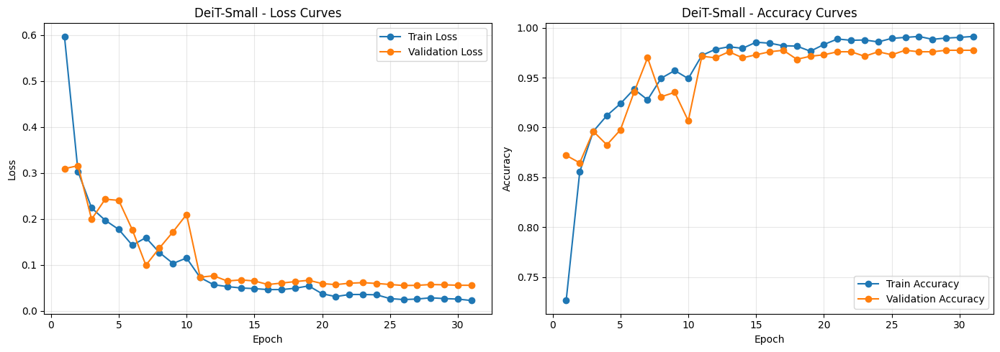


Classification Report - DeiT-Small
              precision    recall  f1-score   support

  Fully Ripe     0.9669    0.9286    0.9474       126
    Overripe     0.9424    0.9704    0.9562       135
    Perished     0.9310    1.0000    0.9643        27
    Semiripe     0.9942    0.9828    0.9884       174
      Unripe     0.9951    1.0000    0.9975       203

    accuracy                         0.9759       665
   macro avg     0.9659    0.9763    0.9708       665
weighted avg     0.9762    0.9759    0.9759       665



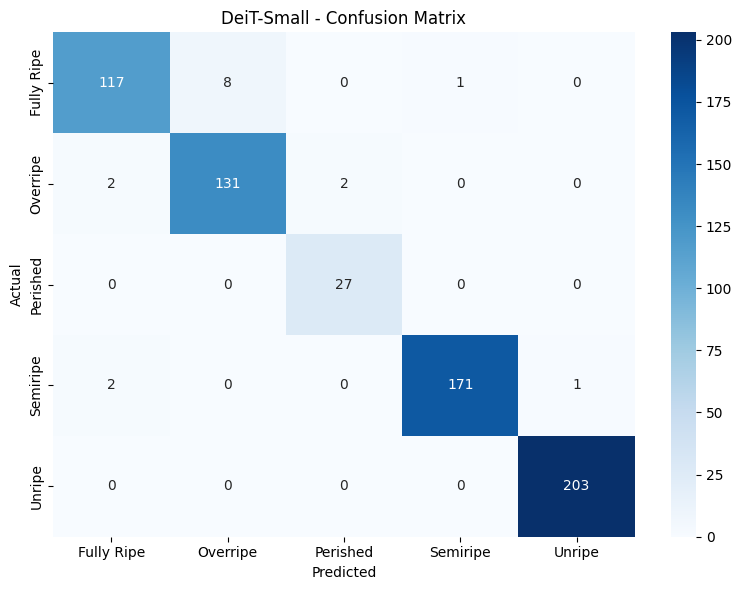


DeiT-Small evaluation complete.
Test Accuracy: 0.9759
Test Loss: 0.0678


In [16]:
deit_test_loss, deit_test_acc, deit_test_preds, deit_test_true = full_evaluation(
    deit_model, "DeiT-Small", test_loader, criterion, DEVICE, class_names, history=deit_history
)

results_summary["DeiT-Small"] = {
    "test_loss": deit_test_loss,
    "test_acc": deit_test_acc,
    "best_epoch": deit_best_epoch,
    "preds": deit_test_preds,
    "true": deit_test_true
}

print("\nDeiT-Small evaluation complete.")
print(f"Test Accuracy: {deit_test_acc:.4f}")
print(f"Test Loss: {deit_test_loss:.4f}")

# Cell 17: Model 5 - Swin Transformer - Setup and Training


In [17]:
set_seed(SEED)

swin_model = timm.create_model("swin_tiny_patch4_window7_224", pretrained=True, num_classes=NUM_CLASSES)
swin_model = swin_model.to(DEVICE)

if MULTI_GPU:
    swin_model = nn.DataParallel(swin_model)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.AdamW(swin_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

print("Starting training: Swin-Tiny", flush=True)
swin_model, swin_history, swin_best_epoch = train_model(
    swin_model, "Swin-Tiny",
    train_loader, val_loader,
    criterion, optimizer, scheduler,
    NUM_EPOCHS, PATIENCE, DEVICE
)

torch.save(swin_model.state_dict(), os.path.join(OUTPUT_DIR, "swin_tiny_best.pth"))
print("Swin-Tiny weights saved.")

models_dict["Swin-Tiny"] = swin_model
histories_dict["Swin-Tiny"] = swin_history

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Starting training: Swin-Tiny

[Swin-Tiny] Epoch 1/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

Validating:   0%|          | 0/21 [00:00<?, ?it/s]

[Swin-Tiny] Epoch 1/35 summary - train_loss: 0.6455 - train_acc: 0.7173 - val_loss: 0.3736 - val_acc: 0.8253 - time: 253.5s
Validation loss improved. Saving best weights.

[Swin-Tiny] Epoch 2/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

... (82 outputs left out)

[Swin-Tiny] Epoch 29/35 summary - train_loss: 0.0276 - train_acc: 0.9890 - val_loss: 0.0648 - val_acc: 0.9759 - time: 266.6s
No improvement for 4 epoch(s).

[Swin-Tiny] Epoch 30/35


Training:   0%|          | 0/97 [00:00<?, ?it/s]

Validating:   0%|          | 0/21 [00:00<?, ?it/s]

[Swin-Tiny] Epoch 30/35 summary - train_loss: 0.0292 - train_acc: 0.9887 - val_loss: 0.0649 - val_acc: 0.9759 - time: 264.8s
No improvement for 5 epoch(s).

Early stopping triggered at epoch 30. Best epoch: 25

Total training time for Swin-Tiny: 131.32 minutes
Swin-Tiny weights saved.


# Cell 18: Model 5 - Swin-Tiny - Full Evaluation


Validating:   0%|          | 0/21 [00:00<?, ?it/s]


Swin-Tiny - Test Loss: 0.0590 - Test Accuracy: 0.9820


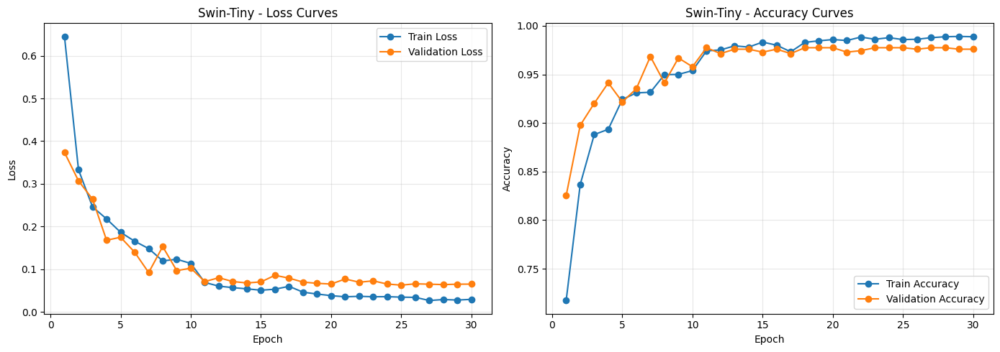


Classification Report - Swin-Tiny
              precision    recall  f1-score   support

  Fully Ripe     0.9677    0.9524    0.9600       126
    Overripe     0.9632    0.9704    0.9668       135
    Perished     0.9310    1.0000    0.9643        27
    Semiripe     0.9942    0.9885    0.9914       174
      Unripe     1.0000    1.0000    1.0000       203

    accuracy                         0.9820       665
   macro avg     0.9712    0.9823    0.9765       665
weighted avg     0.9821    0.9820    0.9820       665



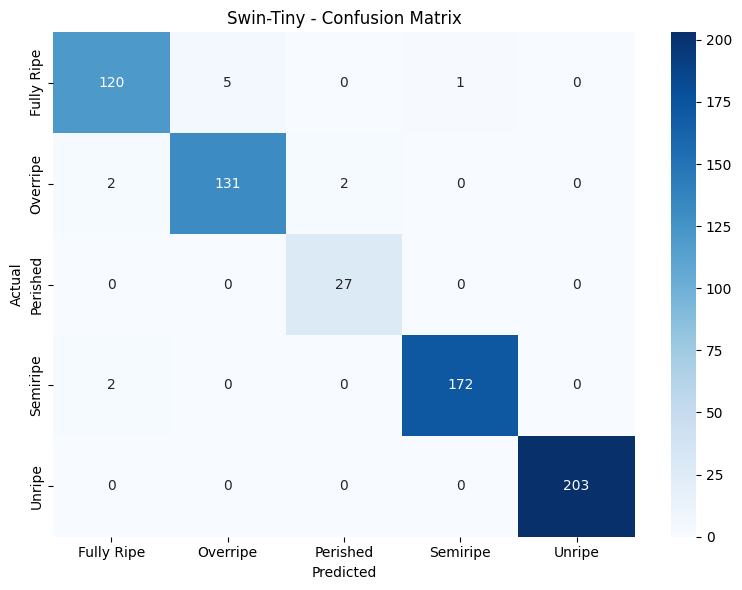


Swin-Tiny evaluation complete.
Test Accuracy: 0.9820
Test Loss: 0.0590


In [18]:
swin_test_loss, swin_test_acc, swin_test_preds, swin_test_true = full_evaluation(
    swin_model, "Swin-Tiny", test_loader, criterion, DEVICE, class_names, history=swin_history
)

results_summary["Swin-Tiny"] = {
    "test_loss": swin_test_loss,
    "test_acc": swin_test_acc,
    "best_epoch": swin_best_epoch,
    "preds": swin_test_preds,
    "true": swin_test_true
}

print("\nSwin-Tiny evaluation complete.")
print(f"Test Accuracy: {swin_test_acc:.4f}")
print(f"Test Loss: {swin_test_loss:.4f}")

# Cell 19: 5-Model Comparison Summary


Model Comparison Summary
          Model  Test Accuracy  Test Loss  Best Epoch
      Swin-Tiny       0.981955   0.058984          25
       ResNet50       0.975940   0.079870          10
     DeiT-Small       0.975940   0.067795          26
    DenseNet121       0.974436   0.061042          25
EfficientNet-B0       0.971429   0.075863          20


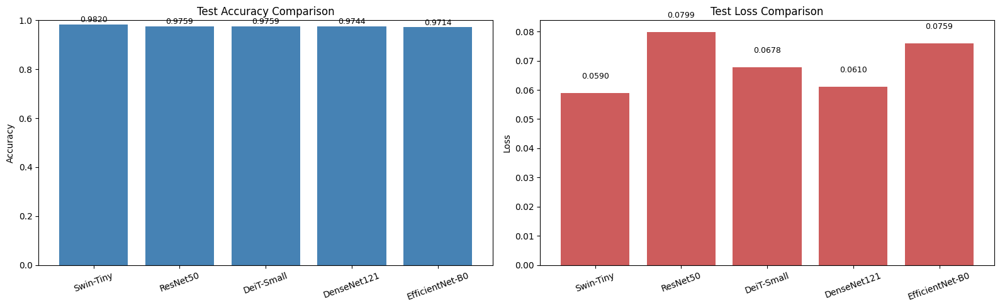


Best performing model: Swin-Tiny


In [19]:
comparison_data = []
for model_name, res in results_summary.items():
    comparison_data.append({
        "Model": model_name,
        "Test Accuracy": res["test_acc"],
        "Test Loss": res["test_loss"],
        "Best Epoch": res["best_epoch"]
    })

comparison_df = pd.DataFrame(comparison_data)
comparison_df = comparison_df.sort_values(by="Test Accuracy", ascending=False).reset_index(drop=True)

print("Model Comparison Summary")
print(comparison_df.to_string(index=False))

comparison_df.to_csv(os.path.join(OUTPUT_DIR, "model_comparison.csv"), index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(comparison_df["Model"], comparison_df["Test Accuracy"], color="steelblue")
axes[0].set_title("Test Accuracy Comparison")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=20)
for i, v in enumerate(comparison_df["Test Accuracy"]):
    axes[0].text(i, v + 0.01, f"{v:.4f}", ha="center", fontsize=9)

axes[1].bar(comparison_df["Model"], comparison_df["Test Loss"], color="indianred")
axes[1].set_title("Test Loss Comparison")
axes[1].set_ylabel("Loss")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(comparison_df["Test Loss"]):
    axes[1].text(i, v + 0.005, f"{v:.4f}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "model_comparison.png"), dpi=150)
plt.show()

best_model_name = comparison_df.iloc[0]["Model"]
print(f"\nBest performing model: {best_model_name}")

# Cell 20: GradCAM Setup and Visualization for all 5 models


Selected sample images for XAI:
  Fully Ripe: image_0_3647.jpg
  Overripe: image_0_1492.jpg
  Perished: image_0_3297.jpg
  Semiripe: image_0_5751 (2).jpg
  Unripe: image_0_4647.jpg


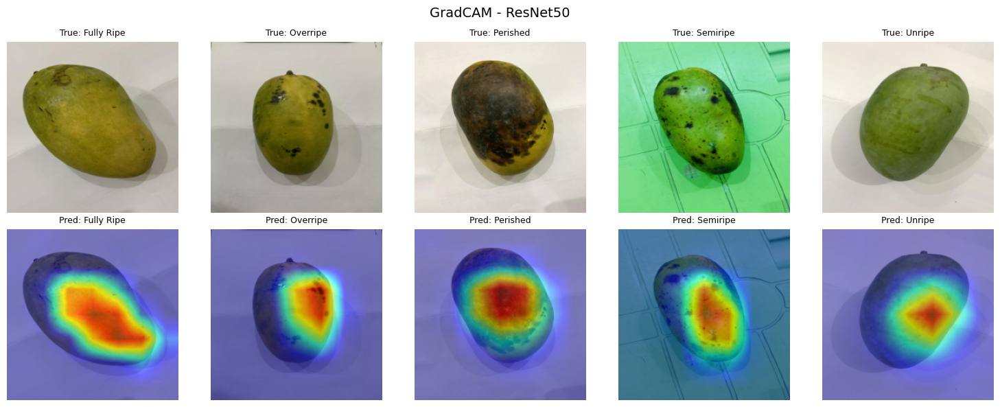

In [20]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def get_unwrapped_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model

def denormalize_image(tensor_img):
    img = tensor_img.clone().cpu().numpy().transpose(1, 2, 0)
    mean = np.array(IMAGENET_MEAN)
    std = np.array(IMAGENET_STD)
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img


def reshape_transform_vit(tensor, height=14, width=14):
    # DeiT: tensor shape (batch, num_tokens, channels), first token is CLS
    result = tensor[:, 1:, :].reshape(tensor.size(0), height, width, tensor.size(2))
    result = result.transpose(2, 3).transpose(1, 2)
    return result


def reshape_transform_swin(tensor, height=7, width=7):
    # Swin final stage: tensor shape (batch, height, width, channels)
    result = tensor.transpose(2, 3).transpose(1, 2)
    return result


def get_target_layer_and_reshape(model, model_name):
    unwrapped = get_unwrapped_model(model)
    if model_name == "ResNet50":
        return [unwrapped.layer4[-1]], None
    elif model_name == "EfficientNet-B0":
        return [unwrapped.features[-1]], None
    elif model_name == "DenseNet121":
        return [unwrapped.features[-1]], None
    elif model_name == "DeiT-Small":
        return [unwrapped.blocks[-1].norm1], reshape_transform_vit
    elif model_name == "Swin-Tiny":
        return [unwrapped.layers[-1].blocks[-1].norm1], reshape_transform_swin
    else:
        raise ValueError("Unknown model name")


def select_sample_images(paths, labels, class_names, n_per_class=1):
    selected_paths = []
    selected_labels = []
    for class_idx in range(len(class_names)):
        idxs = np.where(labels == class_idx)[0]
        chosen = np.random.choice(idxs, size=min(n_per_class, len(idxs)), replace=False)
        for c in chosen:
            selected_paths.append(paths[c])
            selected_labels.append(labels[c])
    return selected_paths, selected_labels


set_seed(SEED)
gradcam_sample_paths, gradcam_sample_labels = select_sample_images(test_paths, test_labels, class_names, n_per_class=1)

print("Selected sample images for XAI:")
for p, l in zip(gradcam_sample_paths, gradcam_sample_labels):
    print(f"  {class_names[l]}: {os.path.basename(p)}")


def generate_gradcam_grid(model, model_name, sample_paths, sample_labels, class_names, device, save_dir=OUTPUT_DIR):
    unwrapped_model = get_unwrapped_model(model)
    unwrapped_model.eval()
    target_layers, reshape_transform = get_target_layer_and_reshape(model, model_name)
    cam = GradCAM(model=unwrapped_model, target_layers=target_layers, reshape_transform=reshape_transform)

    n = len(sample_paths)
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))

    for i, (path, true_label) in enumerate(zip(sample_paths, sample_labels)):
        image = Image.open(path).convert("RGB")
        input_tensor = eval_transform(image).unsqueeze(0).to(device)

        with torch.no_grad():
            output = unwrapped_model(input_tensor)
            pred_label = torch.argmax(output, dim=1).item()

        targets = [ClassifierOutputTarget(pred_label)]
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

        rgb_img = denormalize_image(input_tensor[0])
        cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        axes[0, i].imshow(rgb_img)
        axes[0, i].set_title(f"True: {class_names[true_label]}", fontsize=9)
        axes[0, i].axis("off")

        axes[1, i].imshow(cam_image)
        axes[1, i].set_title(f"Pred: {class_names[pred_label]}", fontsize=9)
        axes[1, i].axis("off")

    plt.suptitle(f"GradCAM - {model_name}", fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{model_name}_gradcam.png"), dpi=150)
    plt.show()


generate_gradcam_grid(resnet_model, "ResNet50", gradcam_sample_paths, gradcam_sample_labels, class_names, DEVICE)

# Cell 21: GradCAM for EfficientNet-B0, DenseNet121, DeiT-Small, Swin-Tiny


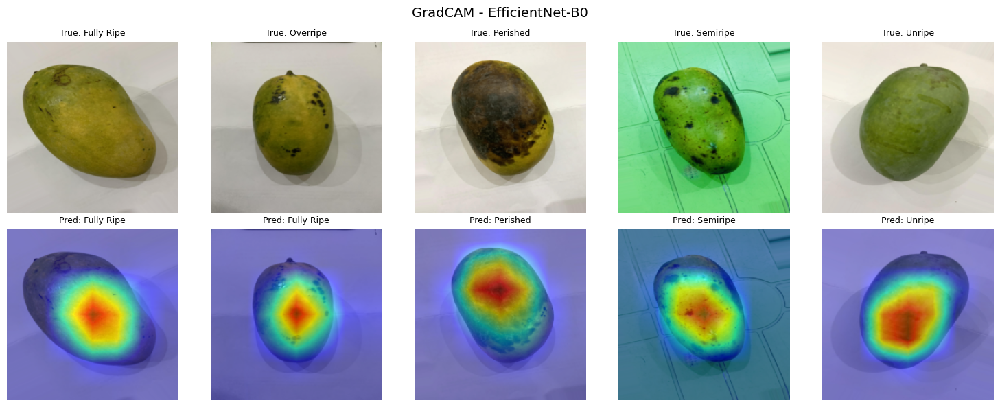

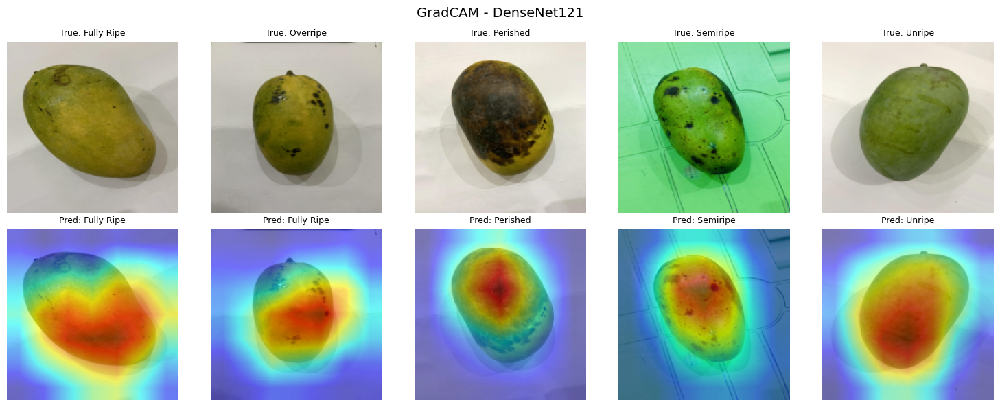

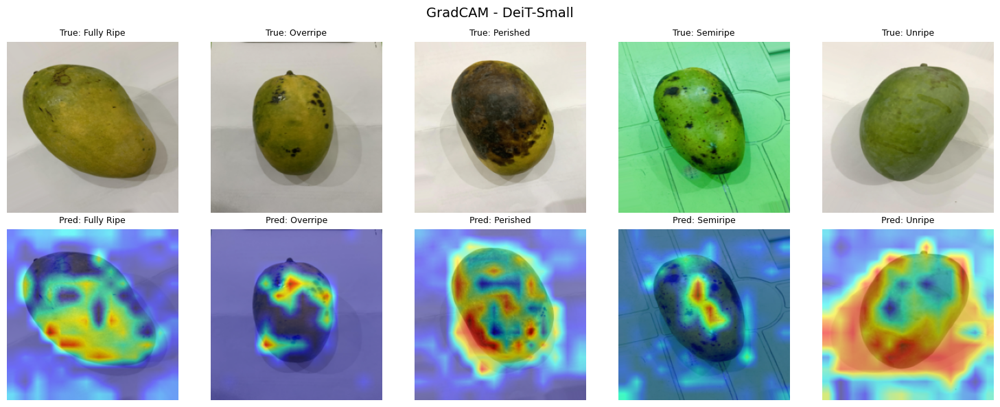

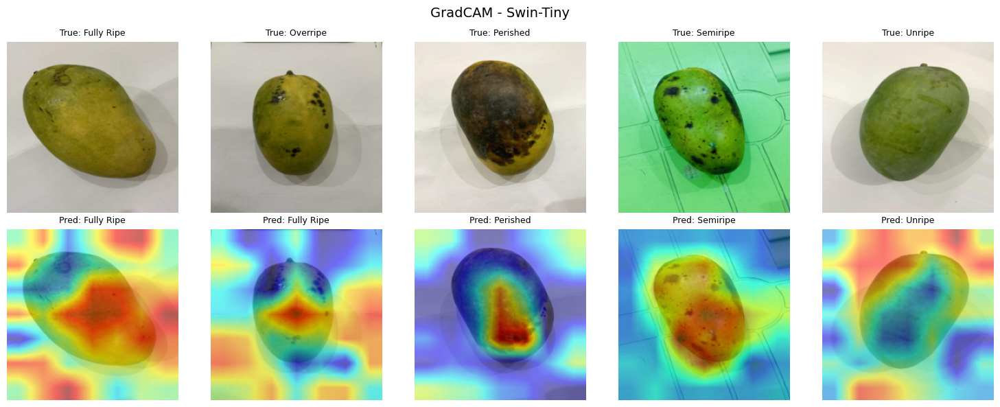

In [21]:
generate_gradcam_grid(effnet_model, "EfficientNet-B0", gradcam_sample_paths, gradcam_sample_labels, class_names, DEVICE)

generate_gradcam_grid(densenet_model, "DenseNet121", gradcam_sample_paths, gradcam_sample_labels, class_names, DEVICE)

generate_gradcam_grid(deit_model, "DeiT-Small", gradcam_sample_paths, gradcam_sample_labels, class_names, DEVICE)

generate_gradcam_grid(swin_model, "Swin-Tiny", gradcam_sample_paths, gradcam_sample_labels, class_names, DEVICE)

# Cell 22: EigenCAM Visualization for all 5 models


Selected sample images for EigenCAM:
  Fully Ripe: image_0_1775.jpg
  Overripe: image_0_8334.jpg
  Perished: image_0_9440.jpg
  Semiripe: image_0_4113.jpg
  Unripe: image_0_6740.jpg


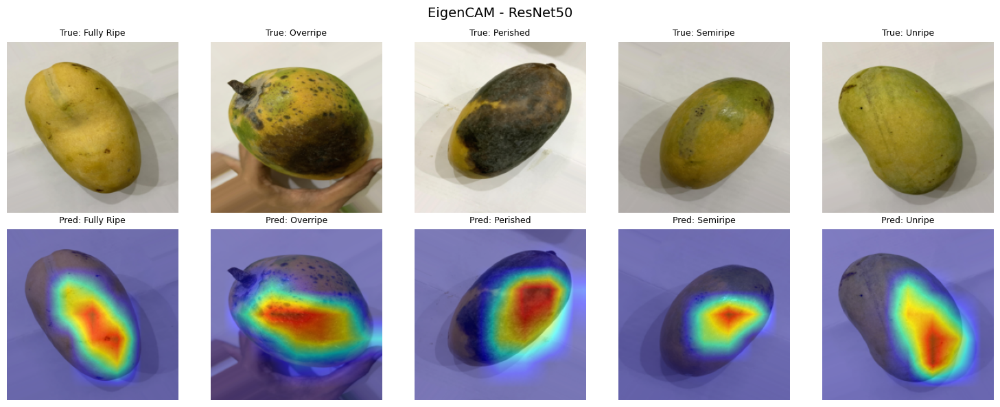

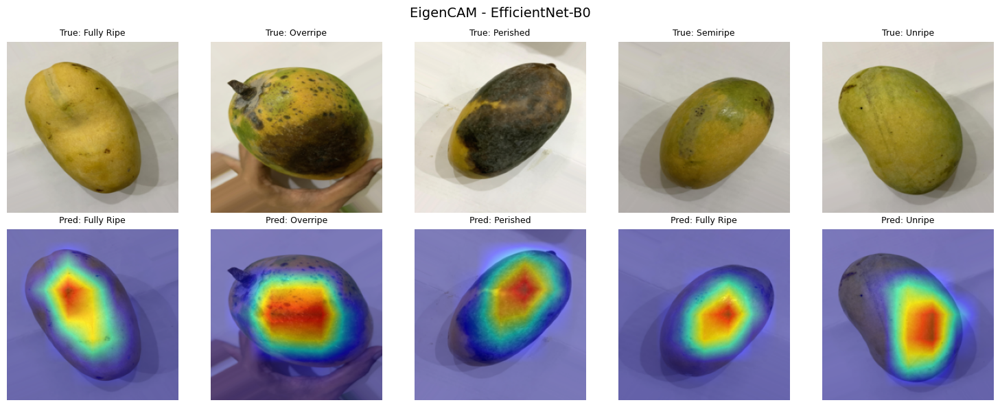

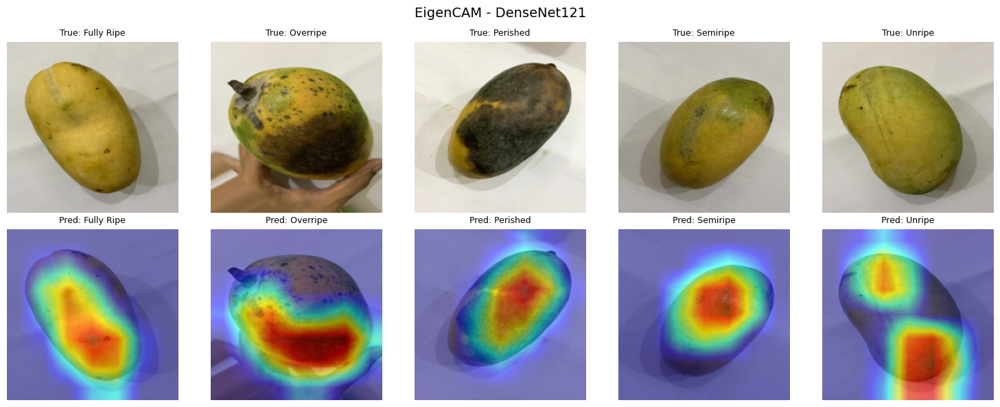

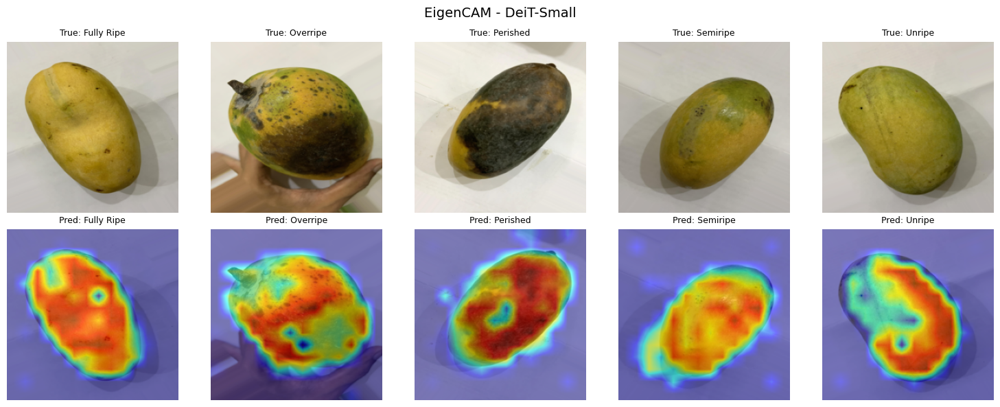

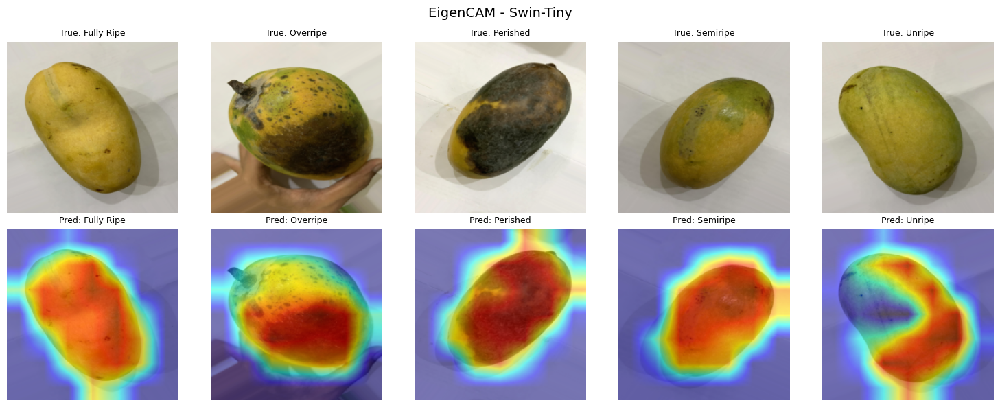

In [22]:
from pytorch_grad_cam import EigenCAM

set_seed(123)
eigencam_sample_paths, eigencam_sample_labels = select_sample_images(test_paths, test_labels, class_names, n_per_class=1)

print("Selected sample images for EigenCAM:")
for p, l in zip(eigencam_sample_paths, eigencam_sample_labels):
    print(f"  {class_names[l]}: {os.path.basename(p)}")


def generate_eigencam_grid(model, model_name, sample_paths, sample_labels, class_names, device, save_dir=OUTPUT_DIR):
    unwrapped_model = get_unwrapped_model(model)
    unwrapped_model.eval()
    target_layers, reshape_transform = get_target_layer_and_reshape(model, model_name)
    cam = EigenCAM(model=unwrapped_model, target_layers=target_layers, reshape_transform=reshape_transform)

    n = len(sample_paths)
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))

    for i, (path, true_label) in enumerate(zip(sample_paths, sample_labels)):
        image = Image.open(path).convert("RGB")
        input_tensor = eval_transform(image).unsqueeze(0).to(device)

        with torch.no_grad():
            output = unwrapped_model(input_tensor)
            pred_label = torch.argmax(output, dim=1).item()

        grayscale_cam = cam(input_tensor=input_tensor)[0]

        rgb_img = denormalize_image(input_tensor[0])
        cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        axes[0, i].imshow(rgb_img)
        axes[0, i].set_title(f"True: {class_names[true_label]}", fontsize=9)
        axes[0, i].axis("off")

        axes[1, i].imshow(cam_image)
        axes[1, i].set_title(f"Pred: {class_names[pred_label]}", fontsize=9)
        axes[1, i].axis("off")

    plt.suptitle(f"EigenCAM - {model_name}", fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{model_name}_eigencam.png"), dpi=150)
    plt.show()


generate_eigencam_grid(resnet_model, "ResNet50", eigencam_sample_paths, eigencam_sample_labels, class_names, DEVICE)
generate_eigencam_grid(effnet_model, "EfficientNet-B0", eigencam_sample_paths, eigencam_sample_labels, class_names, DEVICE)
generate_eigencam_grid(densenet_model, "DenseNet121", eigencam_sample_paths, eigencam_sample_labels, class_names, DEVICE)
generate_eigencam_grid(deit_model, "DeiT-Small", eigencam_sample_paths, eigencam_sample_labels, class_names, DEVICE)
generate_eigencam_grid(swin_model, "Swin-Tiny", eigencam_sample_paths, eigencam_sample_labels, class_names, DEVICE)

# Cell 23: LIME Visualization for all 5 models


Selected sample images for LIME:
  Fully Ripe: image_0_9843.jpg
  Overripe: image_0_4156.jpg
  Perished: image_0_7795.jpg
  Semiripe: image_0_7376.jpg
  Unripe: image_0_8994.jpg


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

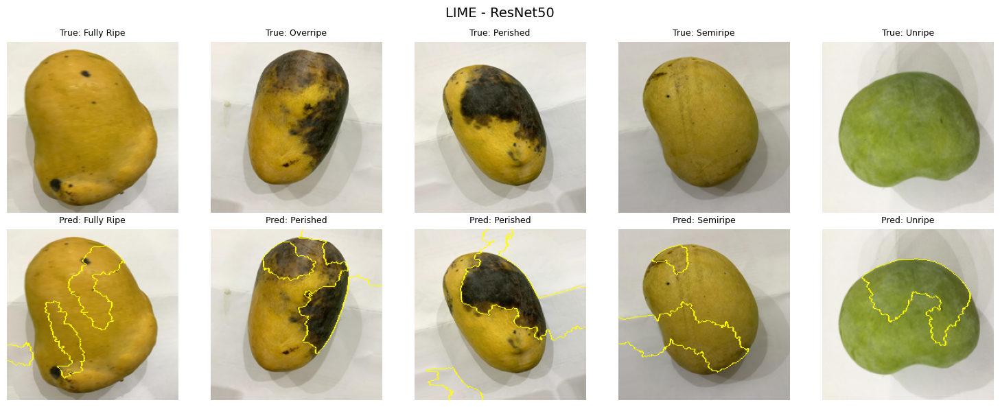

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

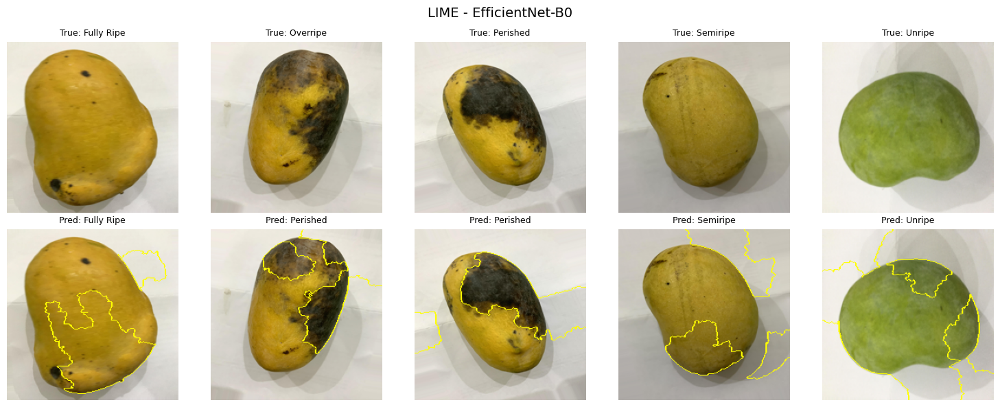

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

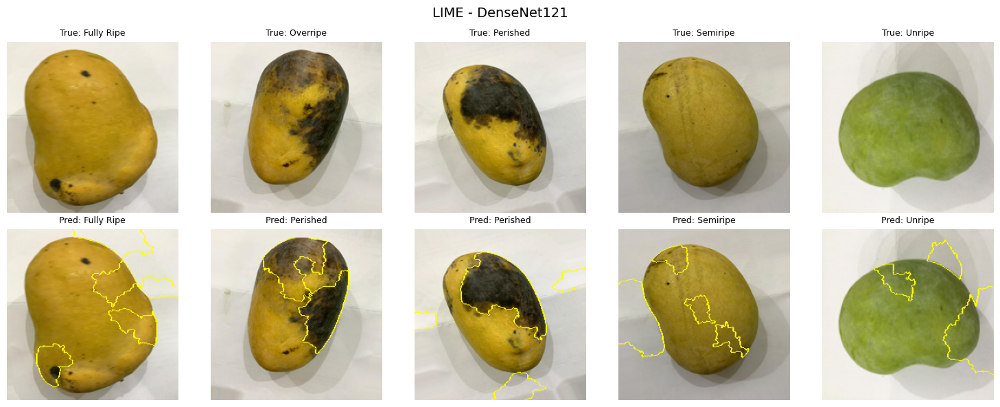

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

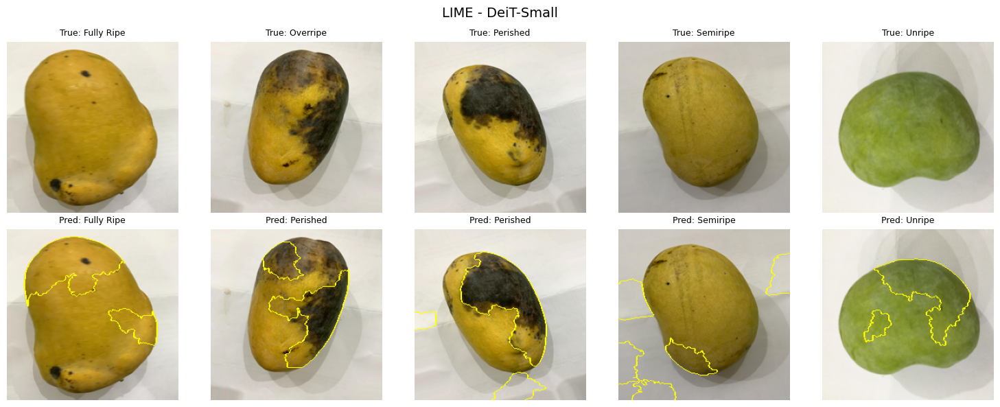

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

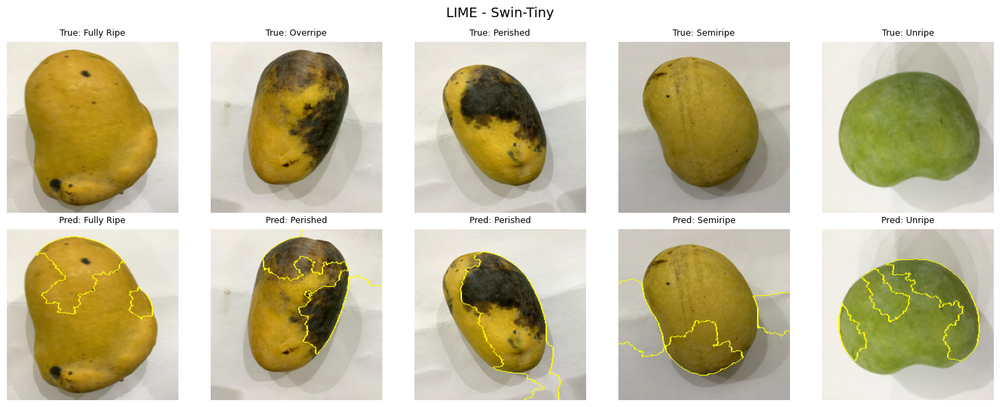

In [23]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

set_seed(7)
lime_sample_paths, lime_sample_labels = select_sample_images(test_paths, test_labels, class_names, n_per_class=1)

print("Selected sample images for LIME:")
for p, l in zip(lime_sample_paths, lime_sample_labels):
    print(f"  {class_names[l]}: {os.path.basename(p)}")


def predict_fn_factory(model, device):
    unwrapped_model = get_unwrapped_model(model)
    unwrapped_model.eval()

    def predict_fn(images):
        batch = []
        for img in images:
            pil_img = Image.fromarray(img.astype(np.uint8))
            tensor_img = eval_transform(pil_img)
            batch.append(tensor_img)
        batch = torch.stack(batch).to(device)

        with torch.no_grad():
            outputs = unwrapped_model(batch)
            probs = torch.softmax(outputs, dim=1)

        return probs.cpu().numpy()

    return predict_fn


def generate_lime_grid(model, model_name, sample_paths, sample_labels, class_names, device, save_dir=OUTPUT_DIR):
    explainer = lime_image.LimeImageExplainer()
    predict_fn = predict_fn_factory(model, device)

    n = len(sample_paths)
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))

    for i, (path, true_label) in enumerate(zip(sample_paths, sample_labels)):
        image = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        image_np = np.array(image)

        explanation = explainer.explain_instance(
            image_np,
            predict_fn,
            top_labels=1,
            hide_color=0,
            num_samples=500,
            random_seed=SEED
        )

        pred_label = explanation.top_labels[0]

        temp, mask = explanation.get_image_and_mask(
            pred_label,
            positive_only=True,
            num_features=5,
            hide_rest=False
        )
        lime_overlay = mark_boundaries(temp / 255.0, mask)

        axes[0, i].imshow(image_np)
        axes[0, i].set_title(f"True: {class_names[true_label]}", fontsize=9)
        axes[0, i].axis("off")

        axes[1, i].imshow(lime_overlay)
        axes[1, i].set_title(f"Pred: {class_names[pred_label]}", fontsize=9)
        axes[1, i].axis("off")

    plt.suptitle(f"LIME - {model_name}", fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{model_name}_lime.png"), dpi=150)
    plt.show()


generate_lime_grid(resnet_model, "ResNet50", lime_sample_paths, lime_sample_labels, class_names, DEVICE)
generate_lime_grid(effnet_model, "EfficientNet-B0", lime_sample_paths, lime_sample_labels, class_names, DEVICE)
generate_lime_grid(densenet_model, "DenseNet121", lime_sample_paths, lime_sample_labels, class_names, DEVICE)
generate_lime_grid(deit_model, "DeiT-Small", lime_sample_paths, lime_sample_labels, class_names, DEVICE)
generate_lime_grid(swin_model, "Swin-Tiny", lime_sample_paths, lime_sample_labels, class_names, DEVICE)

# Cell 24: Ablation Study - Comprehensive 5-Model Comparison


ABLATION STUDY - OVERALL MODEL COMPARISON (5 MODELS)
          Model  Total Params (M)  Trainable Params (M)  Epochs Trained  Best Epoch  Final Train Acc  Final Val Acc  Overfit Gap  Test Acc  Test Loss  Macro Precision  Macro Recall  Macro F1  Weighted F1
      Swin-Tiny             27.52                 27.52              30          25           0.9887         0.9759       0.0128    0.9820     0.0590           0.9712        0.9823    0.9765       0.9820
       ResNet50             23.52                 23.52              15          10           0.9758         0.9744       0.0014    0.9759     0.0799           0.9663        0.9762    0.9707       0.9759
     DeiT-Small             21.67                 21.67              31          26           0.9913         0.9774       0.0139    0.9759     0.0678           0.9659        0.9763    0.9708       0.9759
    DenseNet121              6.96                  6.96              30          25           0.9887         0.9759       0.0128   

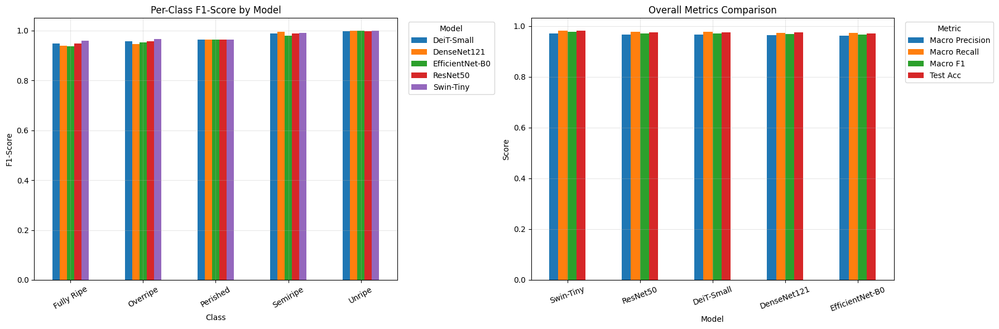


Ablation study artifacts saved:
  ablation_study_overall.csv
  ablation_study_per_class.csv
  ablation_study_comparison.png


In [24]:
from sklearn.metrics import precision_recall_fscore_support

def count_parameters(model):
    unwrapped = get_unwrapped_model(model)
    total_params = sum(p.numel() for p in unwrapped.parameters())
    trainable_params = sum(p.numel() for p in unwrapped.parameters() if p.requires_grad)
    return total_params, trainable_params


ablation_rows = []
per_class_rows = []

for model_name, model in models_dict.items():
    res = results_summary[model_name]
    history = histories_dict[model_name]

    total_params, trainable_params = count_parameters(model)

    precision, recall, f1, support = precision_recall_fscore_support(
        res["true"], res["preds"], average=None, labels=list(range(NUM_CLASSES))
    )
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        res["true"], res["preds"], average="macro"
    )
    weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(
        res["true"], res["preds"], average="weighted"
    )

    epochs_trained = len(history["train_loss"])
    final_train_acc = history["train_acc"][-1]
    final_val_acc = history["val_acc"][-1]
    overfit_gap = final_train_acc - final_val_acc

    ablation_rows.append({
        "Model": model_name,
        "Total Params (M)": round(total_params / 1e6, 2),
        "Trainable Params (M)": round(trainable_params / 1e6, 2),
        "Epochs Trained": epochs_trained,
        "Best Epoch": res["best_epoch"],
        "Final Train Acc": round(final_train_acc, 4),
        "Final Val Acc": round(final_val_acc, 4),
        "Overfit Gap": round(overfit_gap, 4),
        "Test Acc": round(res["test_acc"], 4),
        "Test Loss": round(res["test_loss"], 4),
        "Macro Precision": round(macro_precision, 4),
        "Macro Recall": round(macro_recall, 4),
        "Macro F1": round(macro_f1, 4),
        "Weighted F1": round(weighted_f1, 4),
    })

    for cls_idx, cls_name in enumerate(class_names):
        per_class_rows.append({
            "Model": model_name,
            "Class": cls_name,
            "Precision": round(precision[cls_idx], 4),
            "Recall": round(recall[cls_idx], 4),
            "F1-Score": round(f1[cls_idx], 4),
            "Support": int(support[cls_idx])
        })

ablation_df = pd.DataFrame(ablation_rows).sort_values(by="Test Acc", ascending=False).reset_index(drop=True)
per_class_df = pd.DataFrame(per_class_rows)

print("="*110)
print("ABLATION STUDY - OVERALL MODEL COMPARISON (5 MODELS)")
print("="*110)
print(ablation_df.to_string(index=False))

print("\n" + "="*110)
print("ABLATION STUDY - PER-CLASS PERFORMANCE COMPARISON")
print("="*110)
per_class_pivot = per_class_df.pivot(index="Class", columns="Model", values="F1-Score")
per_class_pivot = per_class_pivot.reindex(class_names)
print("\nF1-Score per class per model:")
print(per_class_pivot.to_string())

ablation_df.to_csv(os.path.join(OUTPUT_DIR, "ablation_study_overall.csv"), index=False)
per_class_df.to_csv(os.path.join(OUTPUT_DIR, "ablation_study_per_class.csv"), index=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

per_class_pivot.plot(kind="bar", ax=axes[0])
axes[0].set_title("Per-Class F1-Score by Model")
axes[0].set_ylabel("F1-Score")
axes[0].set_xlabel("Class")
axes[0].legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(alpha=0.3)

metrics_to_plot = ["Macro Precision", "Macro Recall", "Macro F1", "Test Acc"]
plot_df = ablation_df.set_index("Model")[metrics_to_plot]
plot_df.plot(kind="bar", ax=axes[1])
axes[1].set_title("Overall Metrics Comparison")
axes[1].set_ylabel("Score")
axes[1].legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "ablation_study_comparison.png"), dpi=150)
plt.show()

print("\nAblation study artifacts saved:")
print("  ablation_study_overall.csv")
print("  ablation_study_per_class.csv")
print("  ablation_study_comparison.png")

# Cell 25: Ensemble Model - Soft Voting Across All 5 Models


Computing test set probabilities for each model...
  Processing ResNet50...
  Processing EfficientNet-B0...
  Processing DenseNet121...
  Processing DeiT-Small...
  Processing Swin-Tiny...

All model probabilities computed.
Probability array shape per model: (665, 5)

Ensemble (Soft Voting, 5 models) - Test Accuracy: 0.9789
Ensemble (Soft Voting) - Test Loss: 0.0583

Classification Report - Ensemble (Soft Voting)
              precision    recall  f1-score   support

  Fully Ripe     0.9672    0.9365    0.9516       126
    Overripe     0.9493    0.9704    0.9597       135
    Perished     0.9310    1.0000    0.9643        27
    Semiripe     0.9942    0.9885    0.9914       174
      Unripe     1.0000    1.0000    1.0000       203

    accuracy                         0.9789       665
   macro avg     0.9683    0.9791    0.9734       665
weighted avg     0.9792    0.9789    0.9789       665



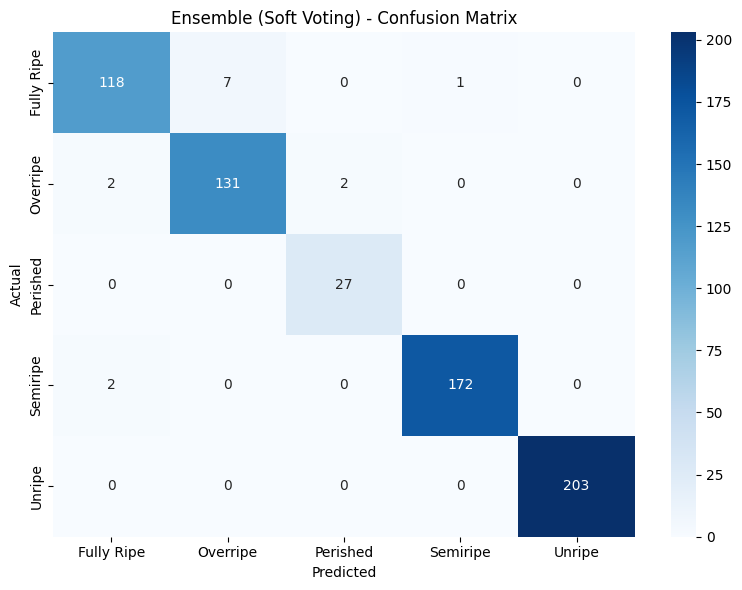

In [25]:
@torch.no_grad()
def get_model_probabilities(model, loader, device):
    unwrapped_model = get_unwrapped_model(model)
    unwrapped_model.eval()

    all_probs = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        outputs = unwrapped_model(images)
        probs = torch.softmax(outputs, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

    all_probs = np.concatenate(all_probs, axis=0)
    all_labels = np.array(all_labels)
    return all_probs, all_labels


print("Computing test set probabilities for each model...")
model_probs = {}
true_labels_ref = None

for model_name, model in models_dict.items():
    print(f"  Processing {model_name}...")
    probs, labels = get_model_probabilities(model, test_loader, DEVICE)
    model_probs[model_name] = probs
    if true_labels_ref is None:
        true_labels_ref = labels
    else:
        assert np.array_equal(true_labels_ref, labels), "Label order mismatch between models"

print("\nAll model probabilities computed.")
print("Probability array shape per model:", model_probs[list(model_probs.keys())[0]].shape)

# Soft voting: simple average of probabilities across all models
ensemble_probs = np.mean(list(model_probs.values()), axis=0)
ensemble_preds = np.argmax(ensemble_probs, axis=1)

ensemble_acc = accuracy_score(true_labels_ref, ensemble_preds)
ensemble_loss = -np.mean(np.log(ensemble_probs[np.arange(len(true_labels_ref)), true_labels_ref] + 1e-12))

print(f"\nEnsemble (Soft Voting, {len(models_dict)} models) - Test Accuracy: {ensemble_acc:.4f}")
print(f"Ensemble (Soft Voting) - Test Loss: {ensemble_loss:.4f}")

print_classification_report(true_labels_ref, ensemble_preds, "Ensemble (Soft Voting)", class_names)
plot_confusion_matrix(true_labels_ref, ensemble_preds, "Ensemble (Soft Voting)", class_names)

results_summary["Ensemble (Soft Voting)"] = {
    "test_loss": ensemble_loss,
    "test_acc": ensemble_acc,
    "best_epoch": None,
    "preds": ensemble_preds,
    "true": true_labels_ref
}

# Cell 26: Updated Comparison Table Including Ensemble


Model Comparison Summary (Including Ensemble)
                 Model  Test Accuracy  Test Loss Best Epoch
             Swin-Tiny       0.981955   0.058984         25
Ensemble (Soft Voting)       0.978947   0.058269        N/A
            DeiT-Small       0.975940   0.067795         26
              ResNet50       0.975940   0.079870         10
           DenseNet121       0.974436   0.061042         25
       EfficientNet-B0       0.971429   0.075863         20


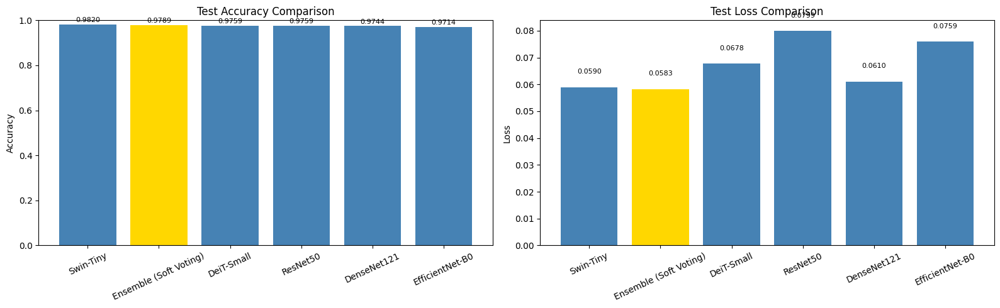


Best performing model overall: Swin-Tiny


In [26]:
comparison_data = []
for model_name, res in results_summary.items():
    comparison_data.append({
        "Model": model_name,
        "Test Accuracy": res["test_acc"],
        "Test Loss": res["test_loss"],
        "Best Epoch": res["best_epoch"] if res["best_epoch"] is not None else "N/A"
    })

comparison_df = pd.DataFrame(comparison_data)
comparison_df = comparison_df.sort_values(by="Test Accuracy", ascending=False).reset_index(drop=True)

print("Model Comparison Summary (Including Ensemble)")
print(comparison_df.to_string(index=False))

comparison_df.to_csv(os.path.join(OUTPUT_DIR, "model_comparison_with_ensemble.csv"), index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bar_colors = ["gold" if "Ensemble" in m else "steelblue" for m in comparison_df["Model"]]

axes[0].bar(comparison_df["Model"], comparison_df["Test Accuracy"], color=bar_colors)
axes[0].set_title("Test Accuracy Comparison")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=25)
for i, v in enumerate(comparison_df["Test Accuracy"]):
    axes[0].text(i, v + 0.01, f"{v:.4f}", ha="center", fontsize=8)

axes[1].bar(comparison_df["Model"], comparison_df["Test Loss"], color=bar_colors)
axes[1].set_title("Test Loss Comparison")
axes[1].set_ylabel("Loss")
axes[1].tick_params(axis="x", rotation=25)
for i, v in enumerate(comparison_df["Test Loss"]):
    axes[1].text(i, v + 0.005, f"{v:.4f}", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "model_comparison_with_ensemble.png"), dpi=150)
plt.show()

best_model_name = comparison_df.iloc[0]["Model"]
print(f"\nBest performing model overall: {best_model_name}")

# Cell 27: Weighted Ensemble - Models Weighted by Individual Test Accuracy


Individual model accuracies (used as weights basis):
  ResNet50: 0.9759
  EfficientNet-B0: 0.9714
  DenseNet121: 0.9744
  DeiT-Small: 0.9759
  Swin-Tiny: 0.9820

Normalized ensemble weights:
  ResNet50: 0.2000
  EfficientNet-B0: 0.1991
  DenseNet121: 0.1997
  DeiT-Small: 0.2000
  Swin-Tiny: 0.2012

Weighted Ensemble - Test Accuracy: 0.9789
Weighted Ensemble - Test Loss: 0.0583

Classification Report - Ensemble (Weighted Voting)
              precision    recall  f1-score   support

  Fully Ripe     0.9672    0.9365    0.9516       126
    Overripe     0.9493    0.9704    0.9597       135
    Perished     0.9310    1.0000    0.9643        27
    Semiripe     0.9942    0.9885    0.9914       174
      Unripe     1.0000    1.0000    1.0000       203

    accuracy                         0.9789       665
   macro avg     0.9683    0.9791    0.9734       665
weighted avg     0.9792    0.9789    0.9789       665



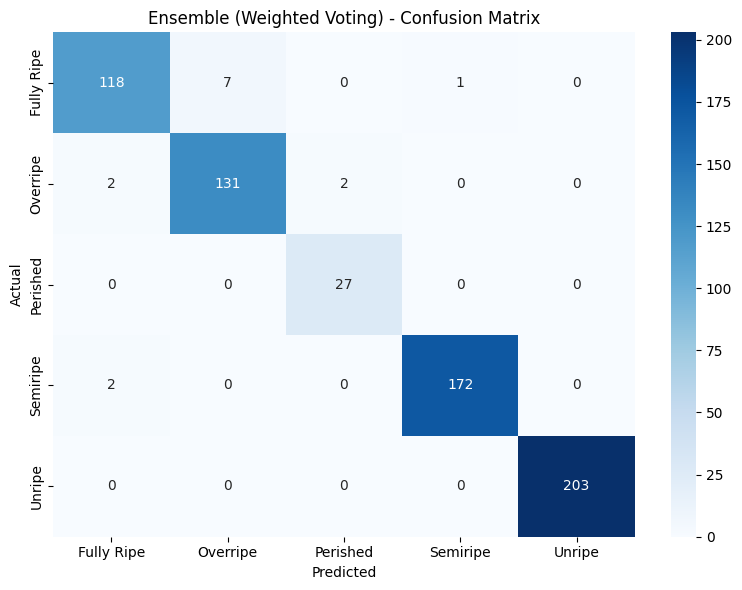

In [27]:
individual_accs = {name: results_summary[name]["test_acc"] for name in models_dict.keys()}

print("Individual model accuracies (used as weights basis):")
for name, acc in individual_accs.items():
    print(f"  {name}: {acc:.4f}")

# Normalize accuracies into weights that sum to 1
total_acc = sum(individual_accs.values())
model_weights = {name: acc / total_acc for name, acc in individual_accs.items()}

print("\nNormalized ensemble weights:")
for name, w in model_weights.items():
    print(f"  {name}: {w:.4f}")

# Weighted average of probabilities
weighted_ensemble_probs = np.zeros_like(list(model_probs.values())[0])
for model_name, probs in model_probs.items():
    weighted_ensemble_probs += model_weights[model_name] * probs

weighted_ensemble_preds = np.argmax(weighted_ensemble_probs, axis=1)

weighted_ensemble_acc = accuracy_score(true_labels_ref, weighted_ensemble_preds)
weighted_ensemble_loss = -np.mean(
    np.log(weighted_ensemble_probs[np.arange(len(true_labels_ref)), true_labels_ref] + 1e-12)
)

print(f"\nWeighted Ensemble - Test Accuracy: {weighted_ensemble_acc:.4f}")
print(f"Weighted Ensemble - Test Loss: {weighted_ensemble_loss:.4f}")

print_classification_report(true_labels_ref, weighted_ensemble_preds, "Ensemble (Weighted Voting)", class_names)
plot_confusion_matrix(true_labels_ref, weighted_ensemble_preds, "Ensemble (Weighted Voting)", class_names)

results_summary["Ensemble (Weighted Voting)"] = {
    "test_loss": weighted_ensemble_loss,
    "test_acc": weighted_ensemble_acc,
    "best_epoch": None,
    "preds": weighted_ensemble_preds,
    "true": true_labels_ref
}

# Cell 28: Final Comparison - All Models and Both Ensembles


Final Model Comparison Summary (All Models + Both Ensembles)
                     Model  Test Accuracy  Test Loss Best Epoch
                 Swin-Tiny       0.981955   0.058984         25
    Ensemble (Soft Voting)       0.978947   0.058269        N/A
Ensemble (Weighted Voting)       0.978947   0.058252        N/A
                  ResNet50       0.975940   0.079870         10
                DeiT-Small       0.975940   0.067795         26
               DenseNet121       0.974436   0.061042         25
           EfficientNet-B0       0.971429   0.075863         20


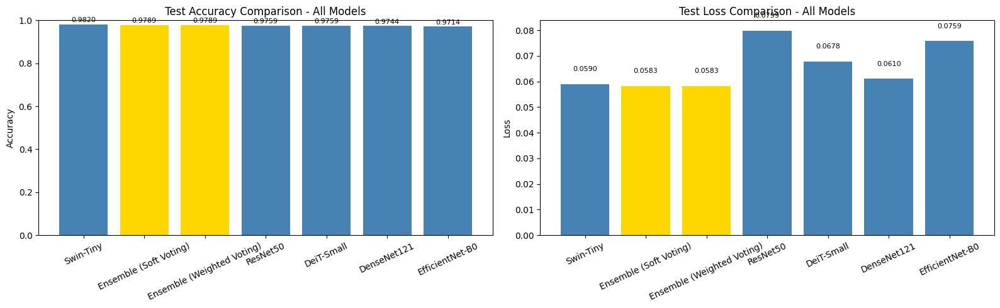


Best performing approach overall: Swin-Tiny (Test Accuracy: 0.9820)

Summary:
  Best single model: Swin-Tiny
  Best ensemble method: Ensemble (Soft Voting)


In [28]:
comparison_data = []
for model_name, res in results_summary.items():
    comparison_data.append({
        "Model": model_name,
        "Test Accuracy": res["test_acc"],
        "Test Loss": res["test_loss"],
        "Best Epoch": res["best_epoch"] if res["best_epoch"] is not None else "N/A"
    })

comparison_df = pd.DataFrame(comparison_data)
comparison_df = comparison_df.sort_values(by="Test Accuracy", ascending=False).reset_index(drop=True)

print("Final Model Comparison Summary (All Models + Both Ensembles)")
print(comparison_df.to_string(index=False))

comparison_df.to_csv(os.path.join(OUTPUT_DIR, "final_comparison_all.csv"), index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bar_colors = ["gold" if "Ensemble" in m else "steelblue" for m in comparison_df["Model"]]

axes[0].bar(comparison_df["Model"], comparison_df["Test Accuracy"], color=bar_colors)
axes[0].set_title("Test Accuracy Comparison - All Models")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=25)
for i, v in enumerate(comparison_df["Test Accuracy"]):
    axes[0].text(i, v + 0.01, f"{v:.4f}", ha="center", fontsize=8)

axes[1].bar(comparison_df["Model"], comparison_df["Test Loss"], color=bar_colors)
axes[1].set_title("Test Loss Comparison - All Models")
axes[1].set_ylabel("Loss")
axes[1].tick_params(axis="x", rotation=25)
for i, v in enumerate(comparison_df["Test Loss"]):
    axes[1].text(i, v + 0.005, f"{v:.4f}", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "final_comparison_all.png"), dpi=150)
plt.show()

best_model_name = comparison_df.iloc[0]["Model"]
best_model_acc = comparison_df.iloc[0]["Test Accuracy"]
print(f"\nBest performing approach overall: {best_model_name} (Test Accuracy: {best_model_acc:.4f})")

print("\nSummary:")
print(f"  Best single model: {comparison_df[~comparison_df['Model'].str.contains('Ensemble')].iloc[0]['Model']}")
print(f"  Best ensemble method: {comparison_df[comparison_df['Model'].str.contains('Ensemble')].iloc[0]['Model']}")